# Carbonate atoll: wave direction on a sinking volcanic island

A volcanic island (+150 m) sinks at 0.5 mm/yr for 600 kyr: its fringing reef
becomes a barrier reef, then, once the summit drowns (~300 kyr), an atoll
(Darwin's sequence). All runs have the same island and carbonate factories;
they differ by the wave climate (and one by the sea level). The reef builders
need wave energy and grow on rims, not on a lagoon floor (open-water index),
so the waves decide where the reef rim grows and whether a lagoon opens. The
runs are described in `README.md` and in the header of each `input-*.yml`;
run `python scripts/make_inputs.py` and `./run_all.sh` first. The plotting
functions are in `scripts/atoll.py`.

In [1]:
import sys
sys.path.insert(0, 'scripts')
import matplotlib.pyplot as plt
import atoll as A

RUNS = ['nowaves', 'ring', 'east', 'season', 'refraction', 'erosion', 'sealevel']
SIMS = ['sim_' + r for r in RUNS]

## Darwin's sequence: waves from all directions (`input-ring.yml`)

Every 150 kyr: the fringing reef around the island (black: shoreline; grey:
-25 m, the limit of the reef builders) grows up as the island sinks and the
island shrinks inside it. After the summit drowns (~300 kyr) the rim takes
the wave energy from every side, the sheltered interior produces less than
the subsidence, and a lagoon opens at the centre (18 m deep at 600 kyr, and
still deepening).

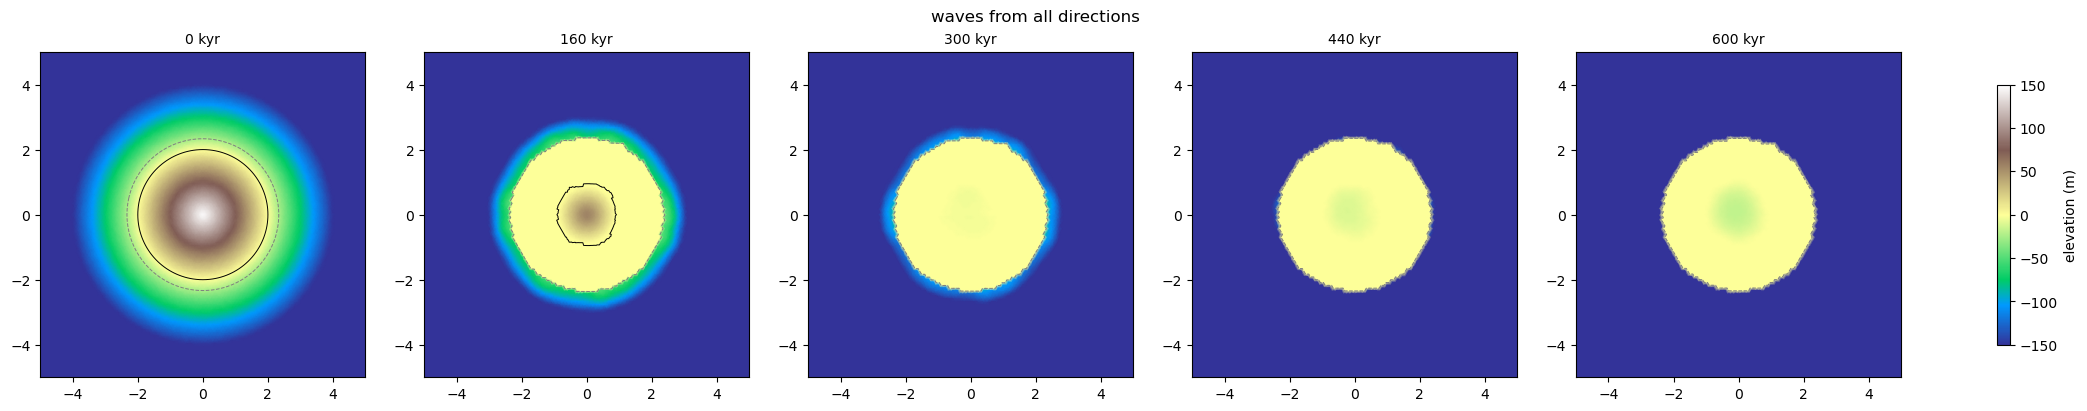

In [2]:
A.evolution('sim_ring', n=5, title='waves from all directions');

## Trade winds from the east (`input-east.yml`)

With one wave direction the reef builders only find energy on the windward
side and on the flanks: the island casts a wave shadow downwind. The windward
reef keeps up, the sheltered interior fills with sand at sea level, and the
leeward margin, without reef, falls behind the subsidence and drowns (down to
-106 m), shedding a slope of carbonate mud.

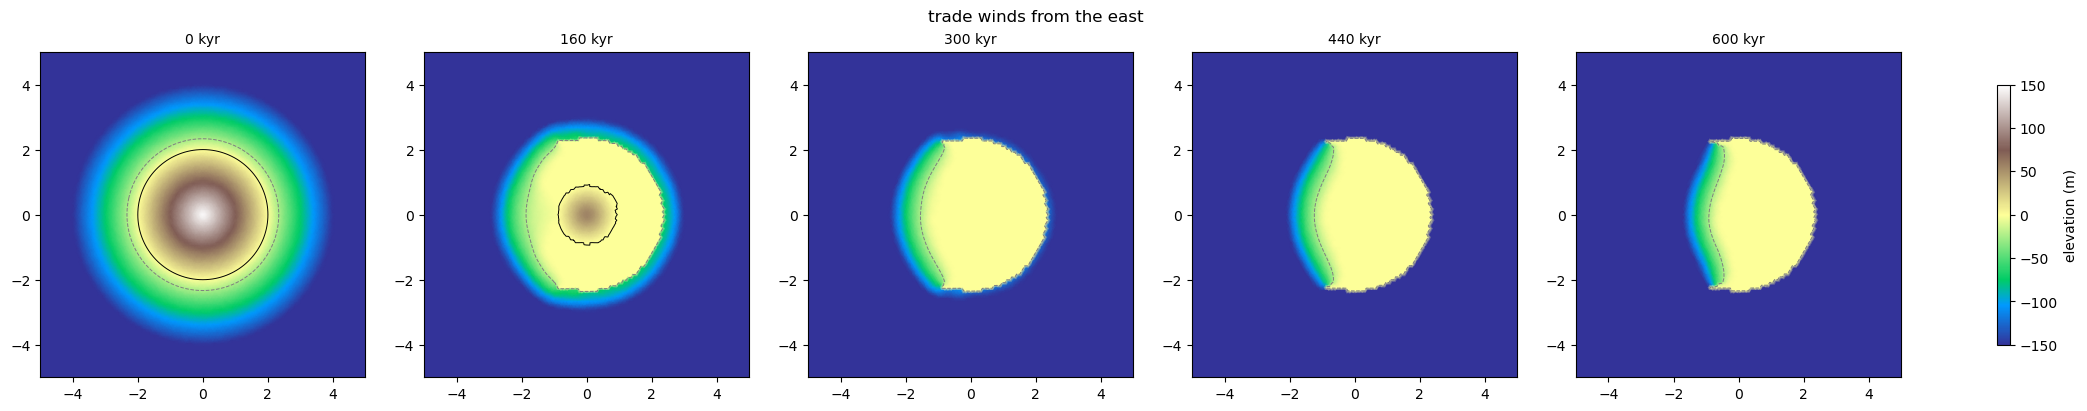

In [3]:
A.evolution('sim_east', n=5, title='trade winds from the east');

## The wave climate decides the shape

The wave energy at the end of each run (the thick cyan line is the 10 m depth
contour), the reef framework thickness and the final elevation.

- **no waves**: the reef grows wherever the light allows and the interior
  keeps up: a flat platform at sea level, no lagoon;
- **ring** (eight directions): a reef rim all around and a lagoon 18 m deep
  at the centre;
- **east**: a windward crescent reef, a sand platform behind it, the leeward
  margin drowned;
- **season** (east 70 %, south-south-west 30 %): reef rims facing both
  swells; the interior receives enough energy to keep up, and only the
  sheltered north-west margin lags;
- **refraction**: practically the same as **east** (refraction turns the
  waves towards the shore on the flanks, but the wave solve has no
  diffraction, so it cannot carry energy into the shadow behind the island);
- **erosion**: the eroded reef, moved as carbonate sand (`rubble`), half fills
  the drowned lee (-58 m instead of -106 m);
- **sealevel**: see below.

Loose carbonate (sand and mud, 3-4 km3) now exceeds the reef framework
(1.4-3 km3) in every run.

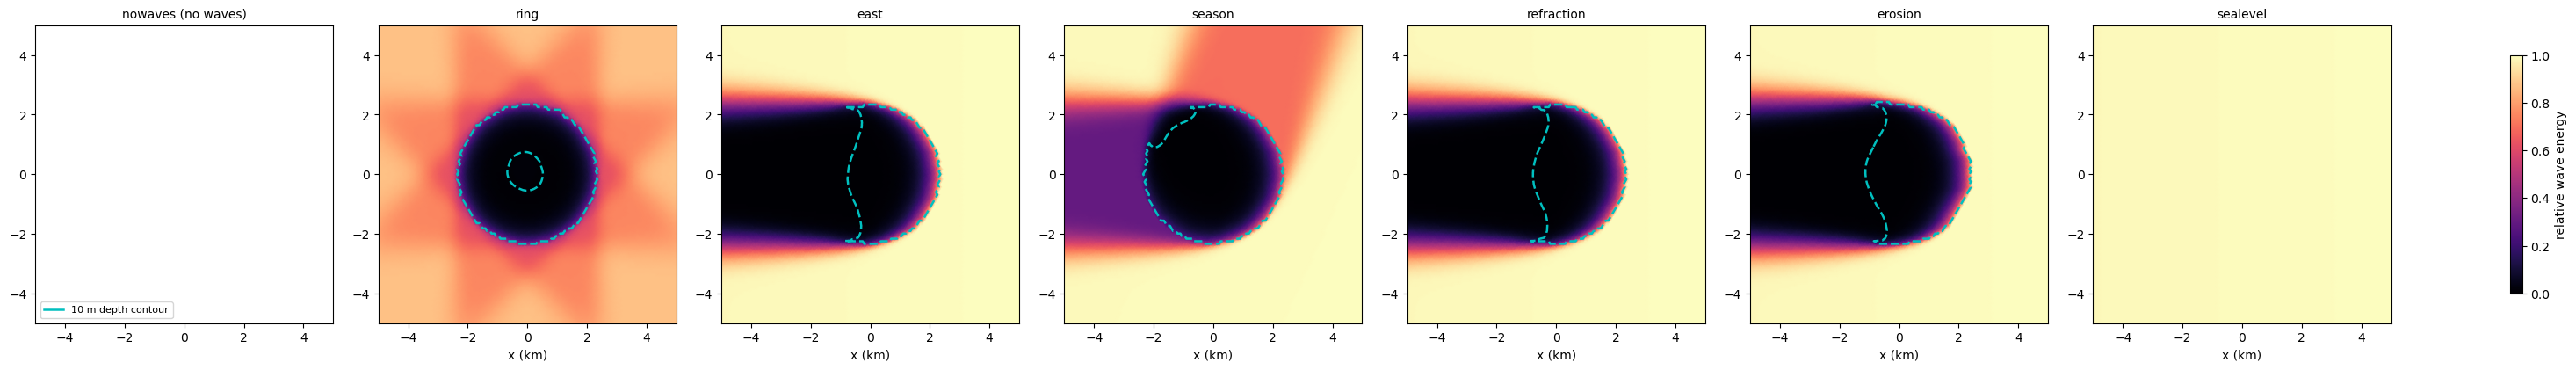

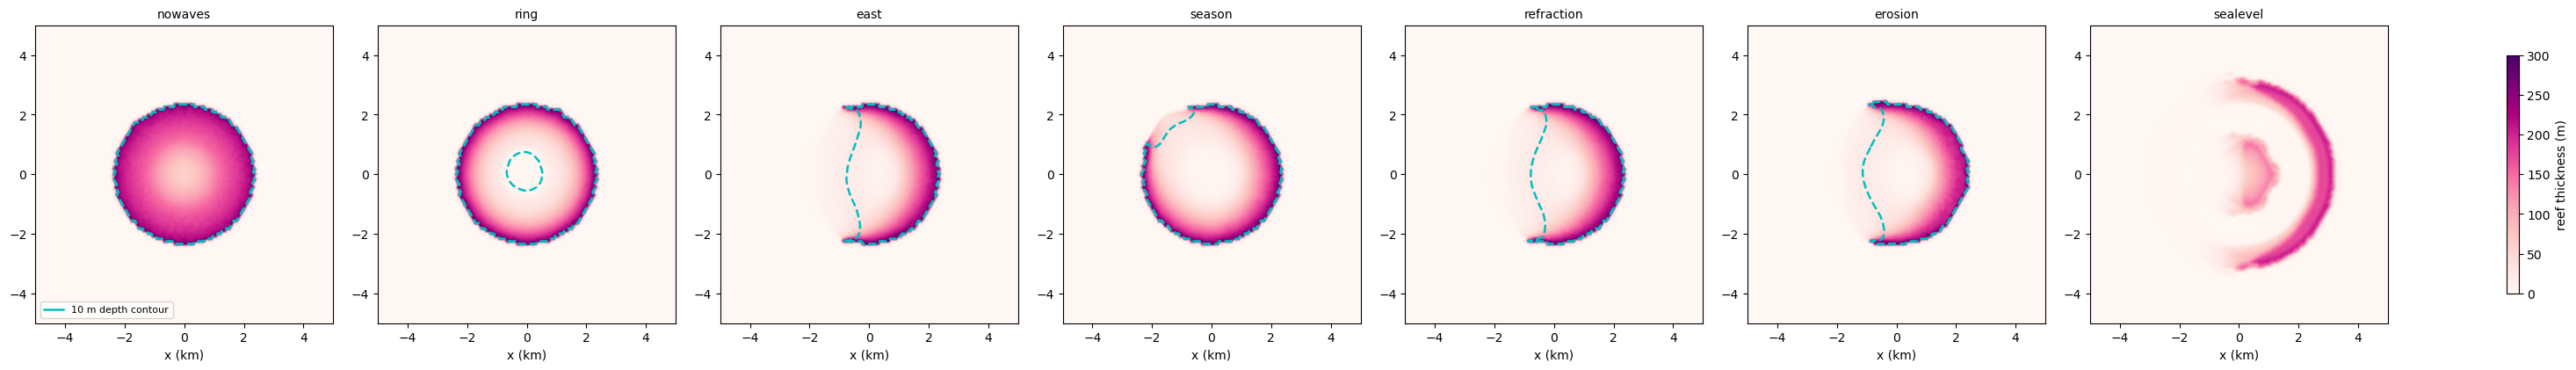

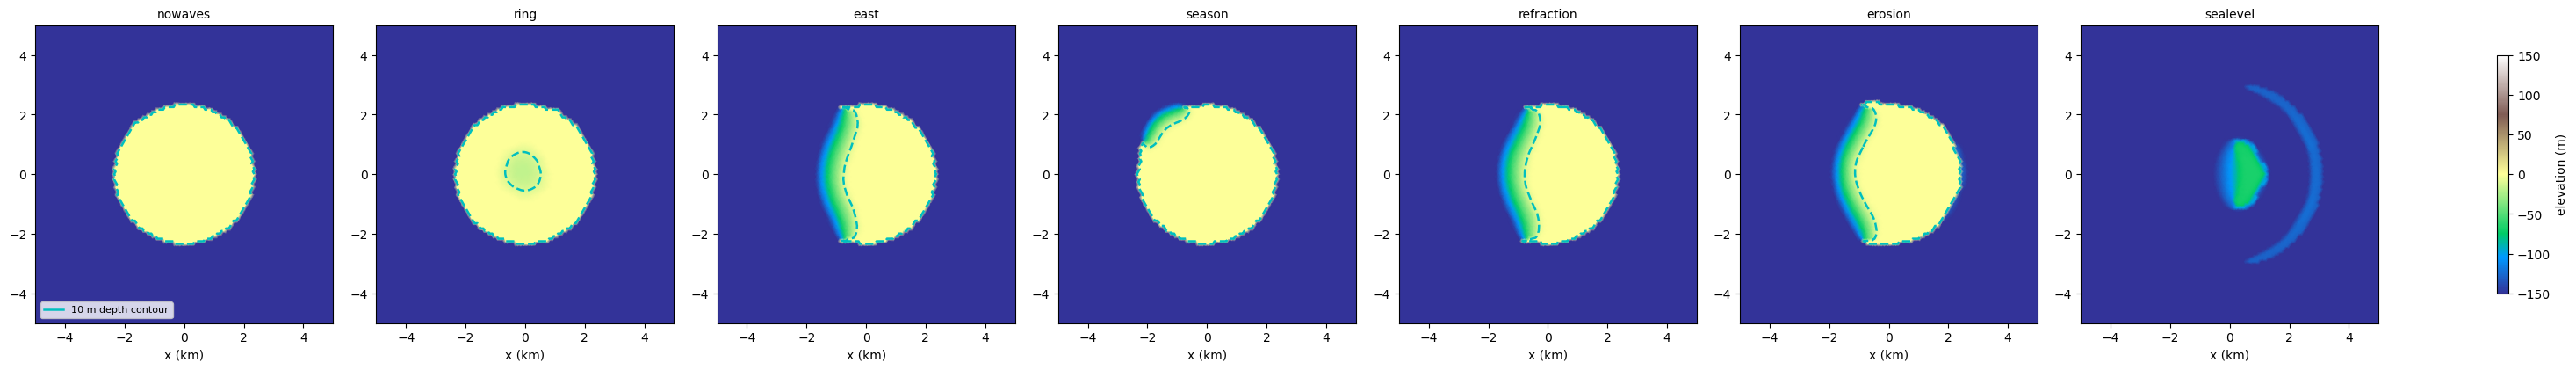

In [4]:
A.compare(SIMS, RUNS, 'waveE')
A.compare(SIMS, RUNS, 'reef')
A.compare(SIMS, RUNS, 'elev');

Sections through the centre of the island, west-east (along the trade winds)
and south-north, coloured by lithology (volcanic sand yellow and mud grey,
carbonate sand light blue, carbonate mud dark blue, reef pink). The ring
atoll has reef only in its rims, carbonate sand behind them and carbonate mud
in the lagoon; with the trade winds the reef stacks on the windward side and
the lee builds a slope of carbonate mud.

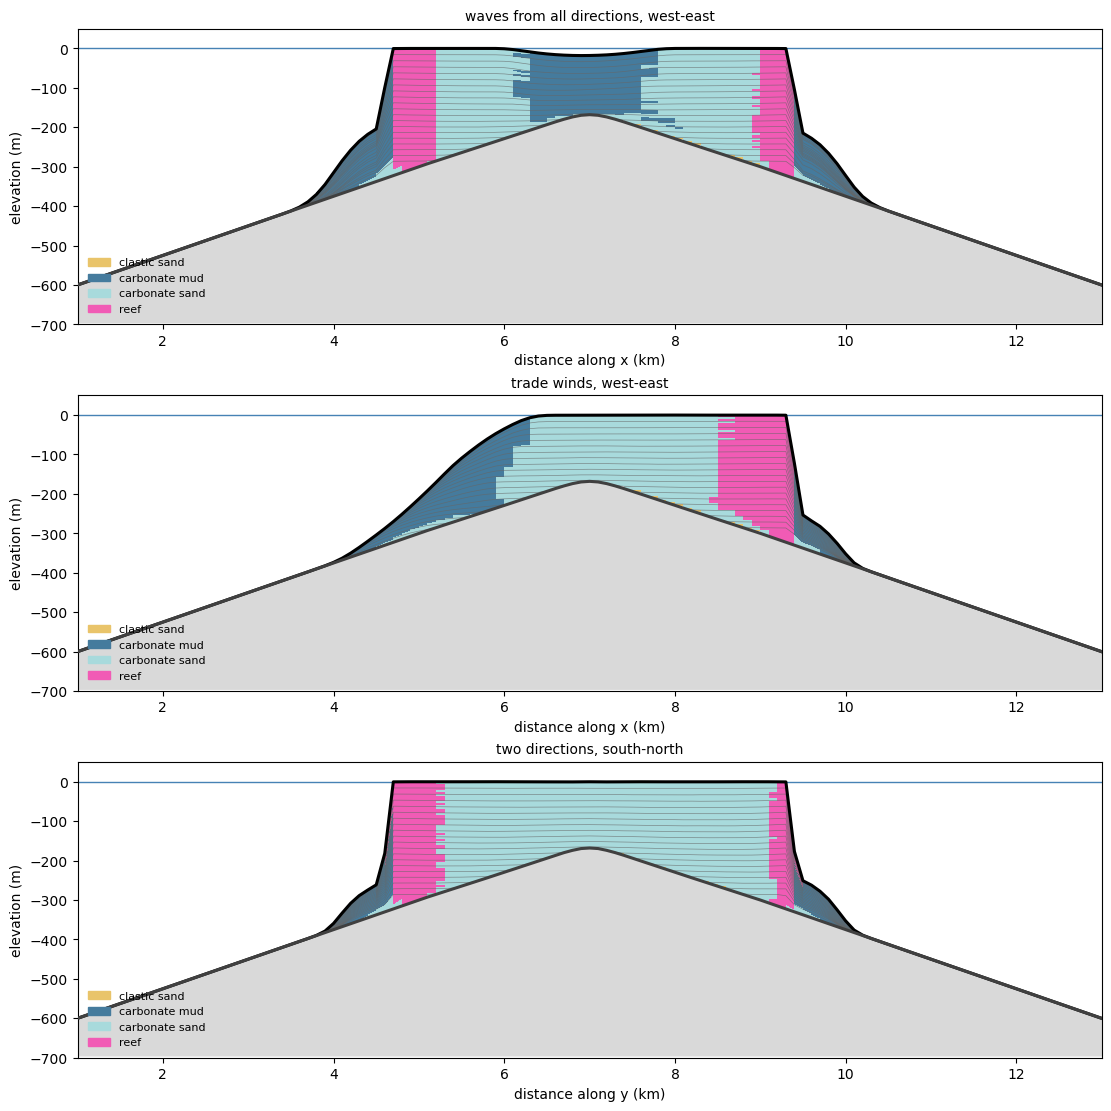

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(11, 11), constrained_layout=True)
A.section('sim_ring', 'x', ax=ax[0], title='waves from all directions, west-east')
A.section('sim_east', 'x', ax=ax[1], title='trade winds, west-east')
A.section('sim_season', 'y', ax=ax[2], title='two directions, south-north');

## Glacial sea level (`input-sealevel.yml`)

The trade-wind run under the Quaternary sea level of Spratt & Lisiecki (2016,
long stack, 0-600 ka, shifted to 0 m at present). The lowstands (down to
-139 m) expose the platform and move the reef down the windward flank, where
it builds a crescent about 3 km from the centre, outside the old platform.
The last deglacial rise (up to 15 mm/yr in the last 20 kyr) is faster than
the reef can follow: the reef builders stop below 25 m, and once the old
platform top is deeper than that nothing shallow is left to grow on. The atoll
drowns (highest point -67 m at present): a drowned atoll. Faster reef growth
does not save it (10 mm/yr still drowns): it is the depth window and the rate
of the rise that decide; for a reef that keeps up, start the run on a
shallower platform or give the reef factory a deeper depth window.

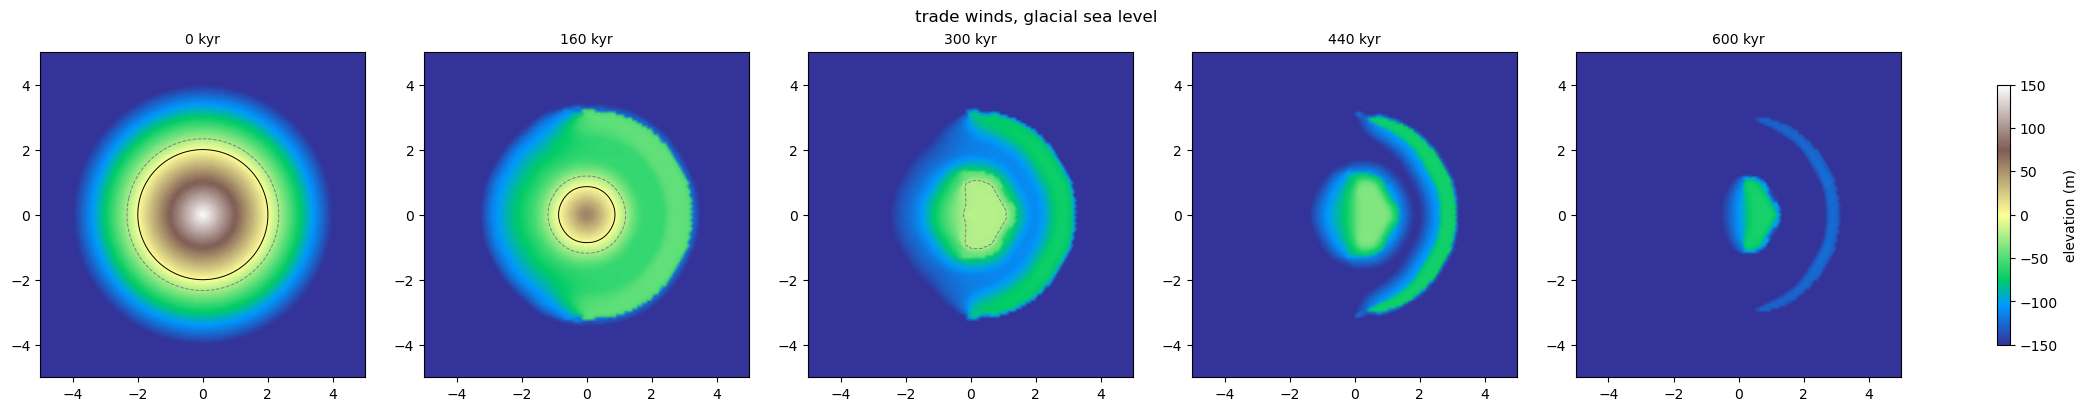

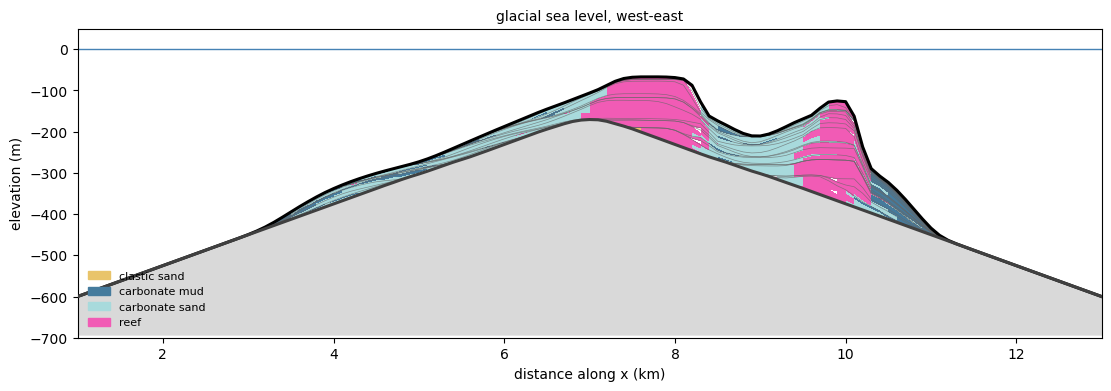

In [6]:
A.evolution('sim_sealevel', n=5, title='trade winds, glacial sea level')
A.section('sim_sealevel', 'x', title='glacial sea level, west-east');